# Lab 12 - Train and Evaluate a Pedestrian Detector

In this lab, you will fine-tune a small pretrained YOLO detector on the prepared pedestrian dataset, inspect its evaluation results, and test it on unseen images.

## Objectives

- Reuse the verified dataset from Lab 11 or prepare it again after a runtime reset.
- Fine-tune a pretrained detector with a GPU.
- Read mAP at IoU 0.50 and mAP across IoU thresholds.
- Inspect predictions on held-out test images.
- Test the trained detector on one new image or short video.

## GPU runtime

Training requires a GPU runtime. In Google Colab, select **Runtime → Change runtime type → T4 GPU** before running the training cell.

In [1]:
%pip -q install "numpy==1.26.4" "albumentations==1.4.24" "ultralytics==8.3.0"

Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\Alina\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [7]:
#%load_ext autoreload
#%autoreload 2

from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

lab_candidates = [
    Path.cwd(),
    Path.cwd() / 'Lab12',
    Path.cwd() / 'Labs' / 'Obj_detection' / 'Lab12',
    Path('/content/Obj_detection/Lab12'),
    Path('/content/Lab12'),
]
for lab_root in lab_candidates:
    if (lab_root / 'README.md').exists() and (lab_root / 'detection_dataset.py').exists():
        break
else:
    raise FileNotFoundError('Keep all Lab12 files in the same folder.')

if str(lab_root) not in sys.path:
    sys.path.insert(0, str(lab_root))

import detection_dataset as dd
importlib.reload(dd)

workspace = lab_root / 'work'
workspace.mkdir(exist_ok=True)

## 1. Load the prepared dataset

The cell first looks for the augmented dataset created in Lab 11. If it is unavailable, it rebuilds the same fixed split and augmentation locally.

In [8]:
lab11_dataset_root = lab_root.parent / 'Lab11' / 'work' / 'pennfudan_yolo_augmented'
if (lab11_dataset_root / 'data.yaml').exists():
    dataset_root = lab11_dataset_root
    print('Using the augmented dataset from Lab 11.')
else:
    source_root = dd.download_pennfudan(workspace / 'source')
    base_dataset_root = dd.prepare_base_dataset(
        source_root, workspace / 'pennfudan_yolo', seed=2026
    )
    dataset_root = dd.make_augmented_dataset(
        base_dataset_root, workspace / 'pennfudan_yolo_augmented', seed=2026
    )
    print('Prepared a local copy of the dataset.')

data_yaml = dd.write_dataset_yaml(dataset_root)
dataset_summary = dd.validate_yolo_dataset(dataset_root)
for split, counts in dataset_summary.items():
    print(f"{split}: {counts['images']} images, {counts['boxes']} boxes")
print('Data configuration:', data_yaml)

Using the augmented dataset from Lab 11.
train: 238 images, 582 boxes
val: 26 images, 68 boxes
test: 25 images, 64 boxes
Data configuration: C:\Users\Alina\OneDrive\Desktop\СV\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\data.yaml


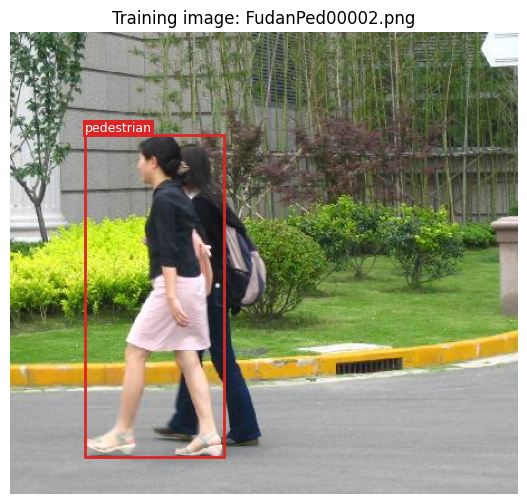

In [9]:
image_array, class_ids, boxes, image_path = dd.load_yolo_sample(dataset_root, 'train', index=0)
figure, axes = plt.subplots(figsize=(7, 6))
dd.plot_yolo_sample(axes, image_array, class_ids, boxes)
axes.set_title(f'Training image: {image_path.name}')
plt.show()

## 2. Check the runtime

The training run uses a small pretrained YOLO model. The explicit augmentations from Lab 11 are already in the training split, so the training cell disables additional random image transformations.

In [10]:
# if not torch.cuda.is_available():
#     raise RuntimeError('No GPU was detected...')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

Using device: cpu


## 3. Fine-tune the detector

The pretrained model already recognizes common visual features. Fine-tuning adapts it to the pedestrian labels and image style in this dataset.

In [15]:
from ultralytics import YOLO

run_root = workspace / 'runs'
run_name = 'pedestrian_yolo11n'
model = YOLO('yolo11n.pt')
training_result = model.train(
    data=str(data_yaml),
    epochs=10,
    imgsz=512,
    device='cpu',
    batch=16,
    workers=2,
    seed=2026,
    deterministic=True,
    project=str(run_root),
    name=run_name,
    exist_ok=True,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.0,
    mosaic=0.0,
    mixup=0.0,
    verbose=True,
)

run_dir = run_root / run_name
best_weights = run_dir / 'weights' / 'best.pt'
if not best_weights.exists():
    raise FileNotFoundError(f'Could not find trained weights at {best_weights}')
print('Best weights:', best_weights)

New https://pypi.org/project/ultralytics/8.4.218 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.0  Python-3.13.14 torch-2.14.0+cpu CPU (12th Gen Intel Core(TM) i5-12500H)
engine\trainer: task=detect, mode=train, model=yolo11n.pt, data=C:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\data.yaml, epochs=10, time=None, patience=100, batch=16, imgsz=512, save=True, save_period=-1, cache=False, device=cpu, workers=2, project=c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\runs, name=pedestrian_yolo11n, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=2026, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, 

train: Scanning C:\Users\Alina\OneDrive\Desktop\СV\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\train\labels... 238 images, 0 backgrounds, 0 corrupt: 100%|██████████| 238/238 [00:00<00:00, 861.79it/s]

train: New cache created: C:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\train\labels.cache


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


C:\Users\Alina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\albumentations\__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.24). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
C:\Users\Alina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
val: Scanning C:\Users\Alina\OneDrive\Desktop\СV\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\val\labels... 26 images, 0 backgrounds, 0 corrupt: 100%|██████████| 26/26 [00:00<00:00, 697.07it/s]

val: New cache created: C:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\val\labels.cache


... (29 outputs left out)

                   all         26         68      0.969      0.912      0.977      0.821



10 epochs completed in 0.171 hours.
Optimizer stripped from c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\runs\pedestrian_yolo11n\weights\last.pt, 5.5MB
Optimizer stripped from c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\runs\pedestrian_yolo11n\weights\best.pt, 5.5MB

Validating c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\runs\pedestrian_yolo11n\weights\best.pt...
Ultralytics 8.3.0  Python-3.13.14 torch-2.14.0+cpu CPU (12th Gen Intel Core(TM) i5-12500H)
YOLO11n summary (fused): 238 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:02<00:00,  2.25s/it]


                   all         26         68      0.968      0.912      0.977      0.821
Speed: 0.7ms preprocess, 71.9ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\runs\pedestrian_yolo11n
Best weights: c:\Users\Alina\OneDrive\Desktop\СV\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\runs\pedestrian_yolo11n\weights\best.pt


## 4. Evaluate the trained model

mAP at IoU 0.50 counts a prediction as correct with a looser overlap requirement. mAP from 0.50 to 0.95 is stricter because it averages results over several overlap thresholds.

In [19]:
best_model = YOLO(best_weights)
validation_metrics = best_model.val(
    data=str(data_yaml),
    split='val',
    imgsz=512,
    batch=16,
    device='cpu',
    plots=True,
    project=str(run_root),
    name=f'{run_name}_validation',
    exist_ok=True,
)
test_metrics = best_model.val(
    data=str(data_yaml),
    split='test',
    imgsz=512,
    batch=16,
    device='cpu',
    plots=True,
    project=str(run_root),
    name=f'{run_name}_test',
    exist_ok=True,
)

print(f"Validation mAP@0.50: {validation_metrics.box.map50:.4f}")
print(f"Validation mAP@0.50:0.95: {validation_metrics.box.map:.4f}")
print(f"Test mAP@0.50: {test_metrics.box.map50:.4f}")
print(f"Test mAP@0.50:0.95: {test_metrics.box.map:.4f}")

Ultralytics 8.3.0  Python-3.13.14 torch-2.14.0+cpu CPU (12th Gen Intel Core(TM) i5-12500H)
YOLO11n summary (fused): 238 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Scanning C:\Users\Alina\OneDrive\Desktop\СV\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\val\labels.cache... 26 images, 0 backgrounds, 0 corrupt: 100%|██████████| 26/26 [00:00<?, ?it/s]
C:\Users\Alina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:01<00:00,  1.33it/s]


                   all         26         68      0.969      0.911      0.977      0.827
Speed: 1.6ms preprocess, 43.2ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\runs\pedestrian_yolo11n_validation
Ultralytics 8.3.0  Python-3.13.14 torch-2.14.0+cpu CPU (12th Gen Intel Core(TM) i5-12500H)


val: Scanning C:\Users\Alina\OneDrive\Desktop\СV\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\test\labels... 25 images, 0 backgrounds, 0 corrupt: 100%|██████████| 25/25 [00:00<00:00, 665.19it/s]

val: New cache created: C:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab11\work\pennfudan_yolo_augmented\test\labels.cache



C:\Users\Alina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:01<00:00,  1.14it/s]


                   all         25         64      0.964      0.842      0.929      0.816
Speed: 1.8ms preprocess, 54.1ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\runs\pedestrian_yolo11n_test
Validation mAP@0.50: 0.9766
Validation mAP@0.50:0.95: 0.8274
Test mAP@0.50: 0.9295
Test mAP@0.50:0.95: 0.8164


results.png


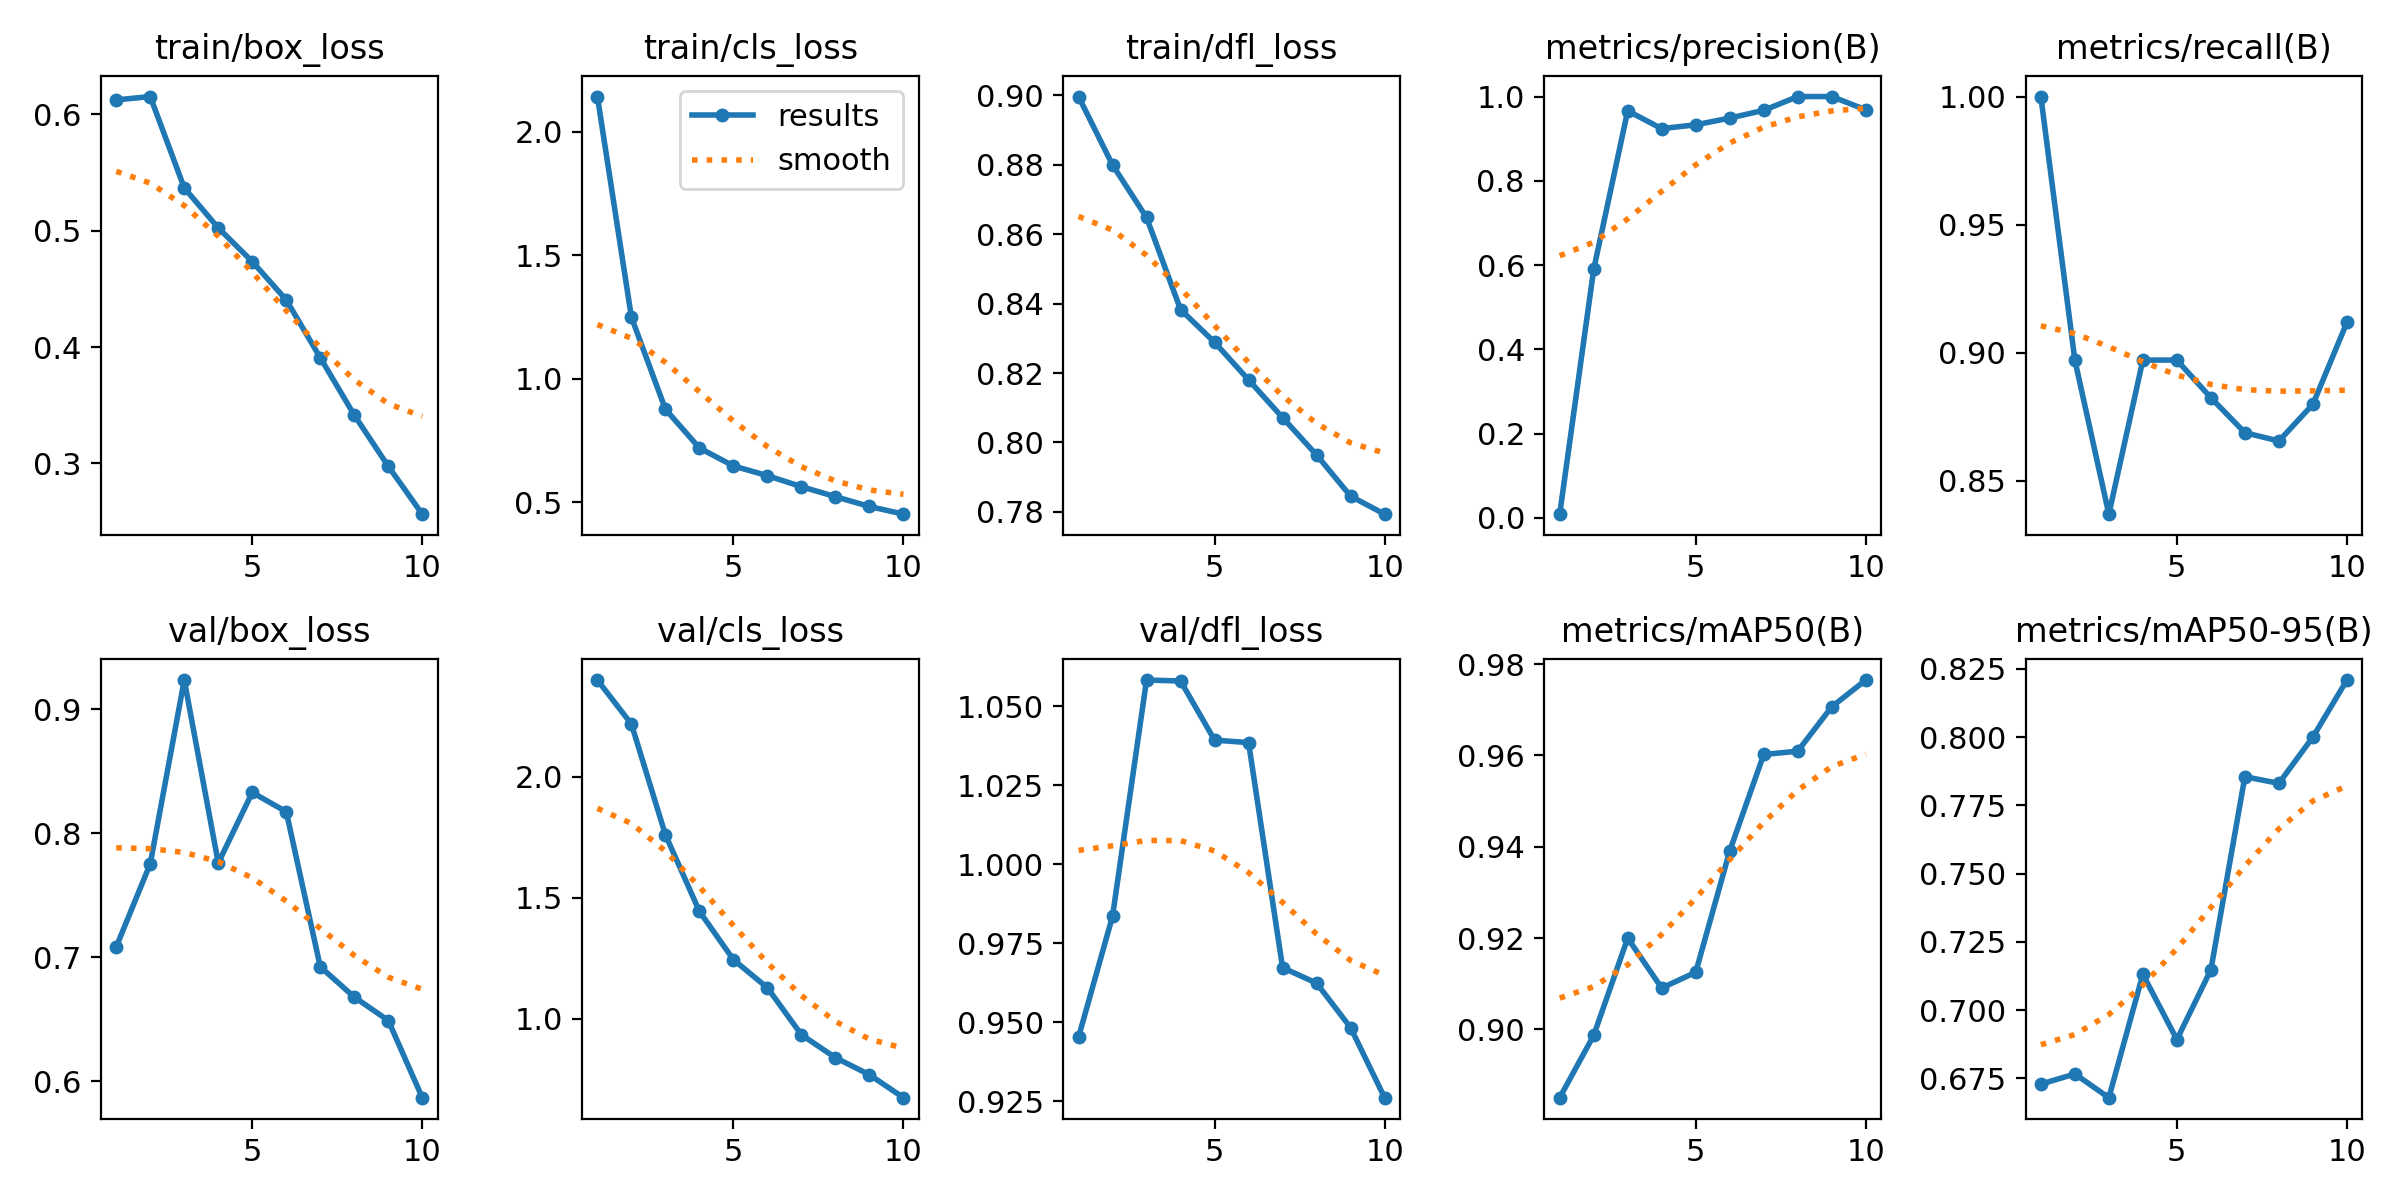

PR_curve.png


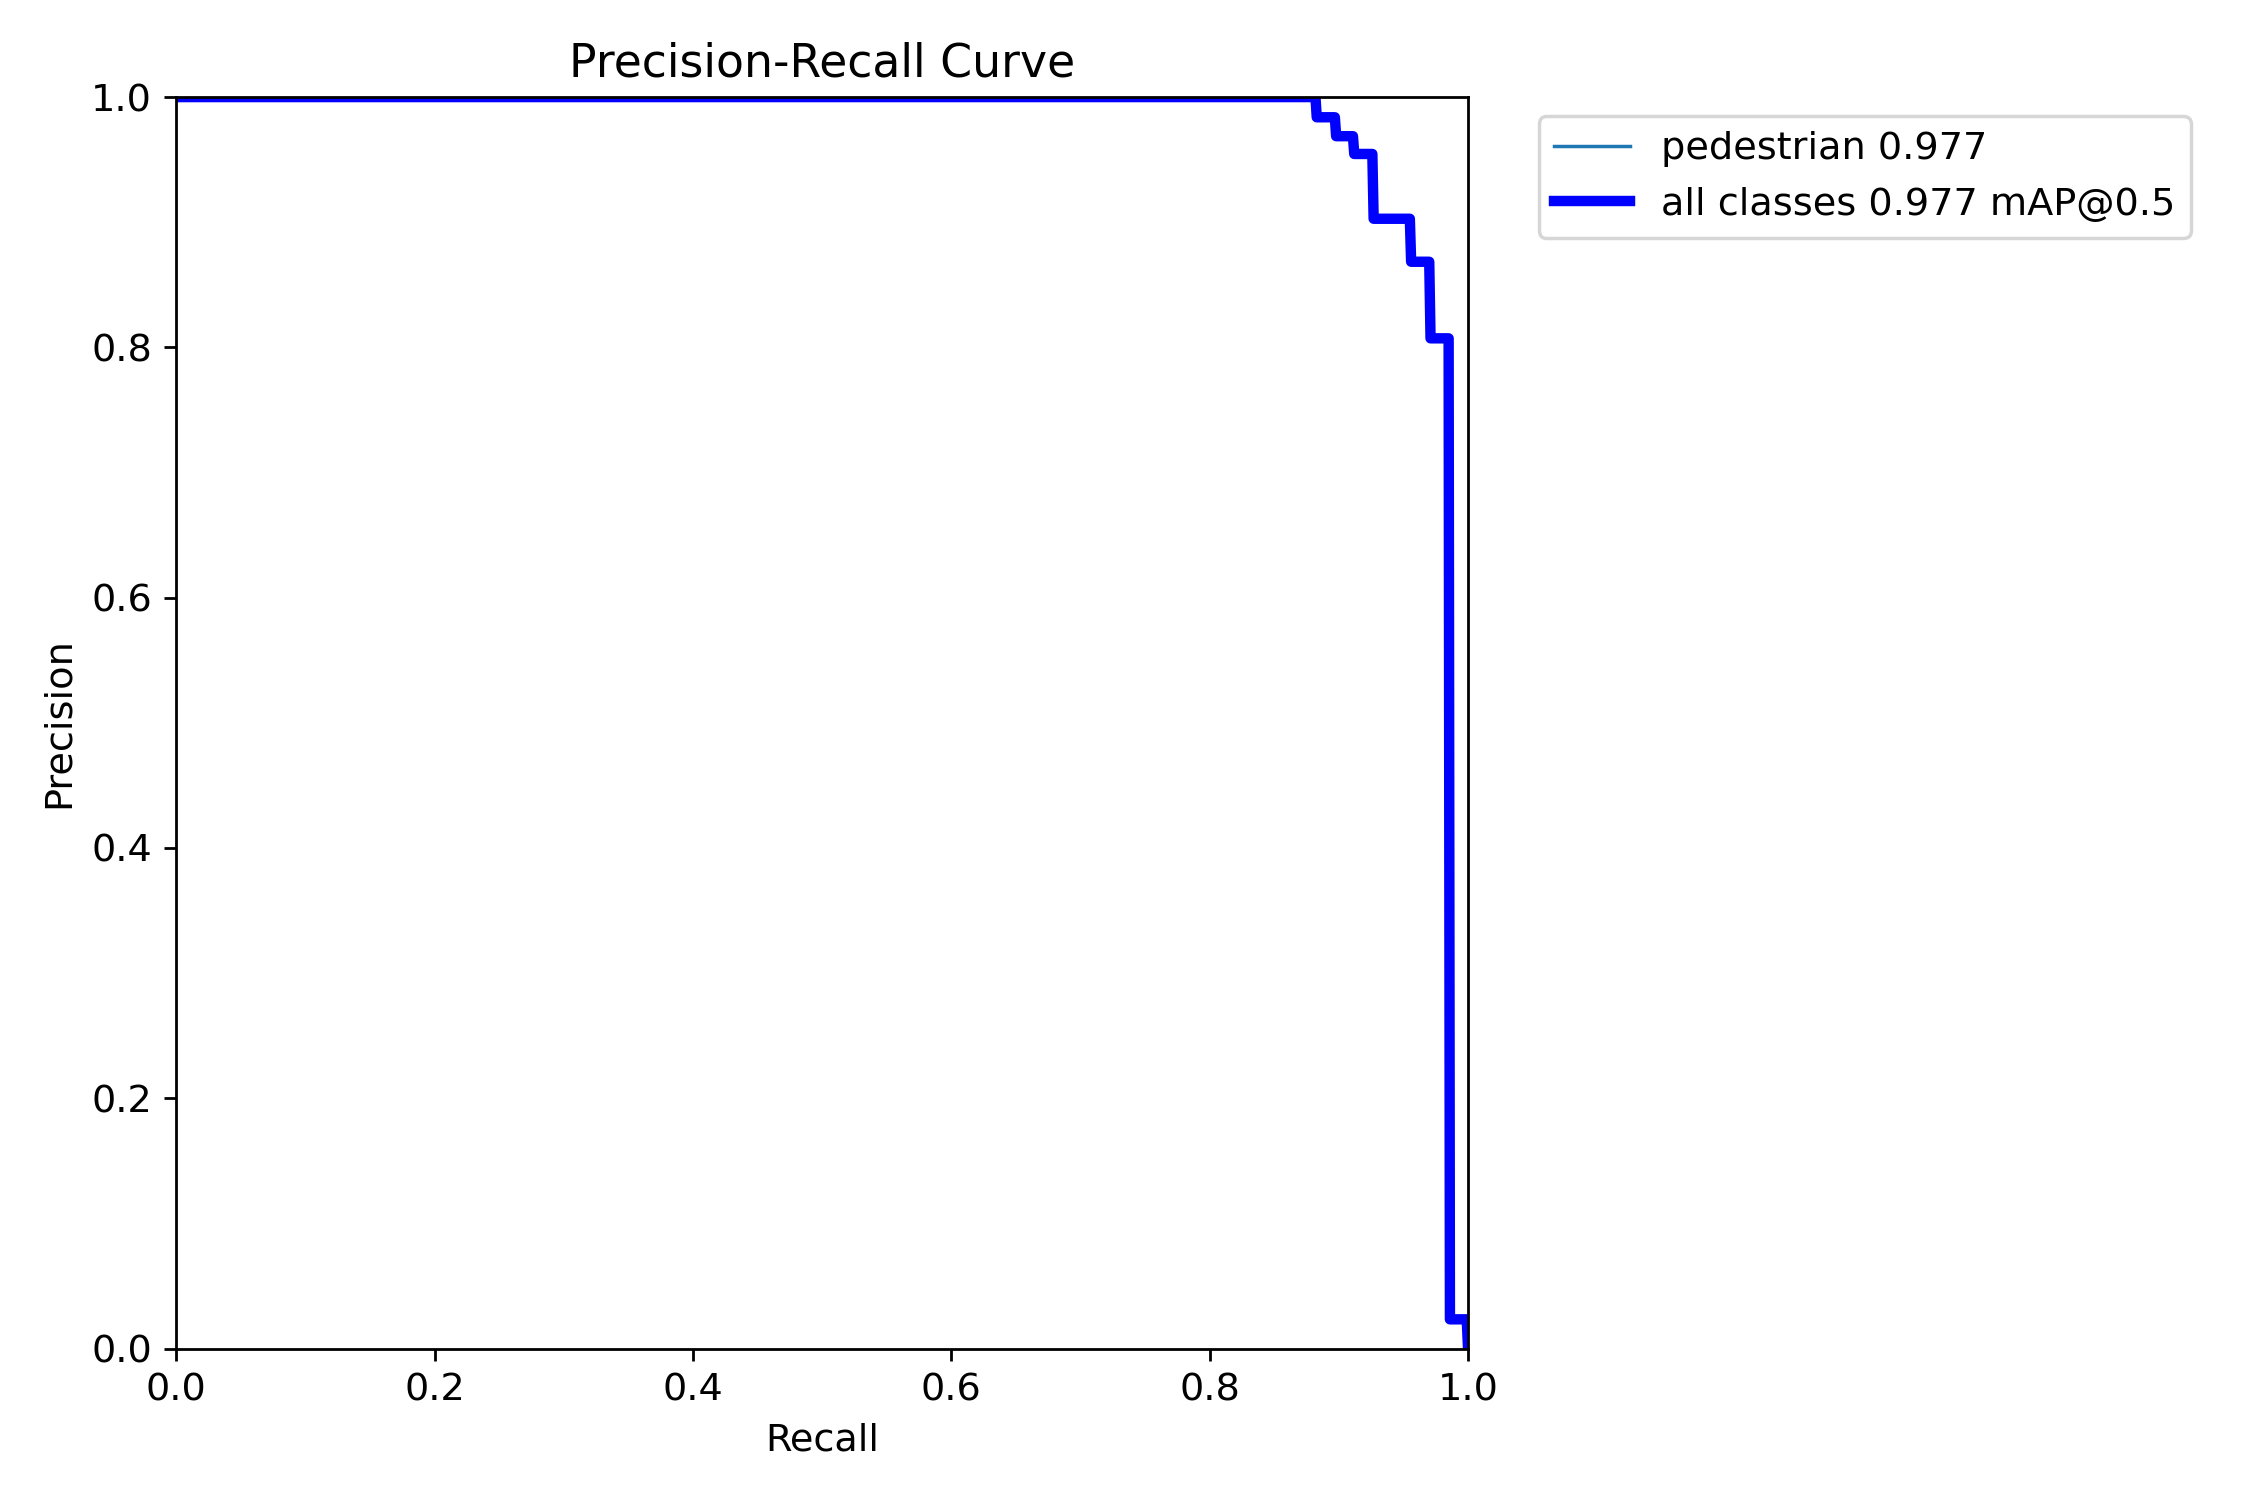

confusion_matrix_normalized.png


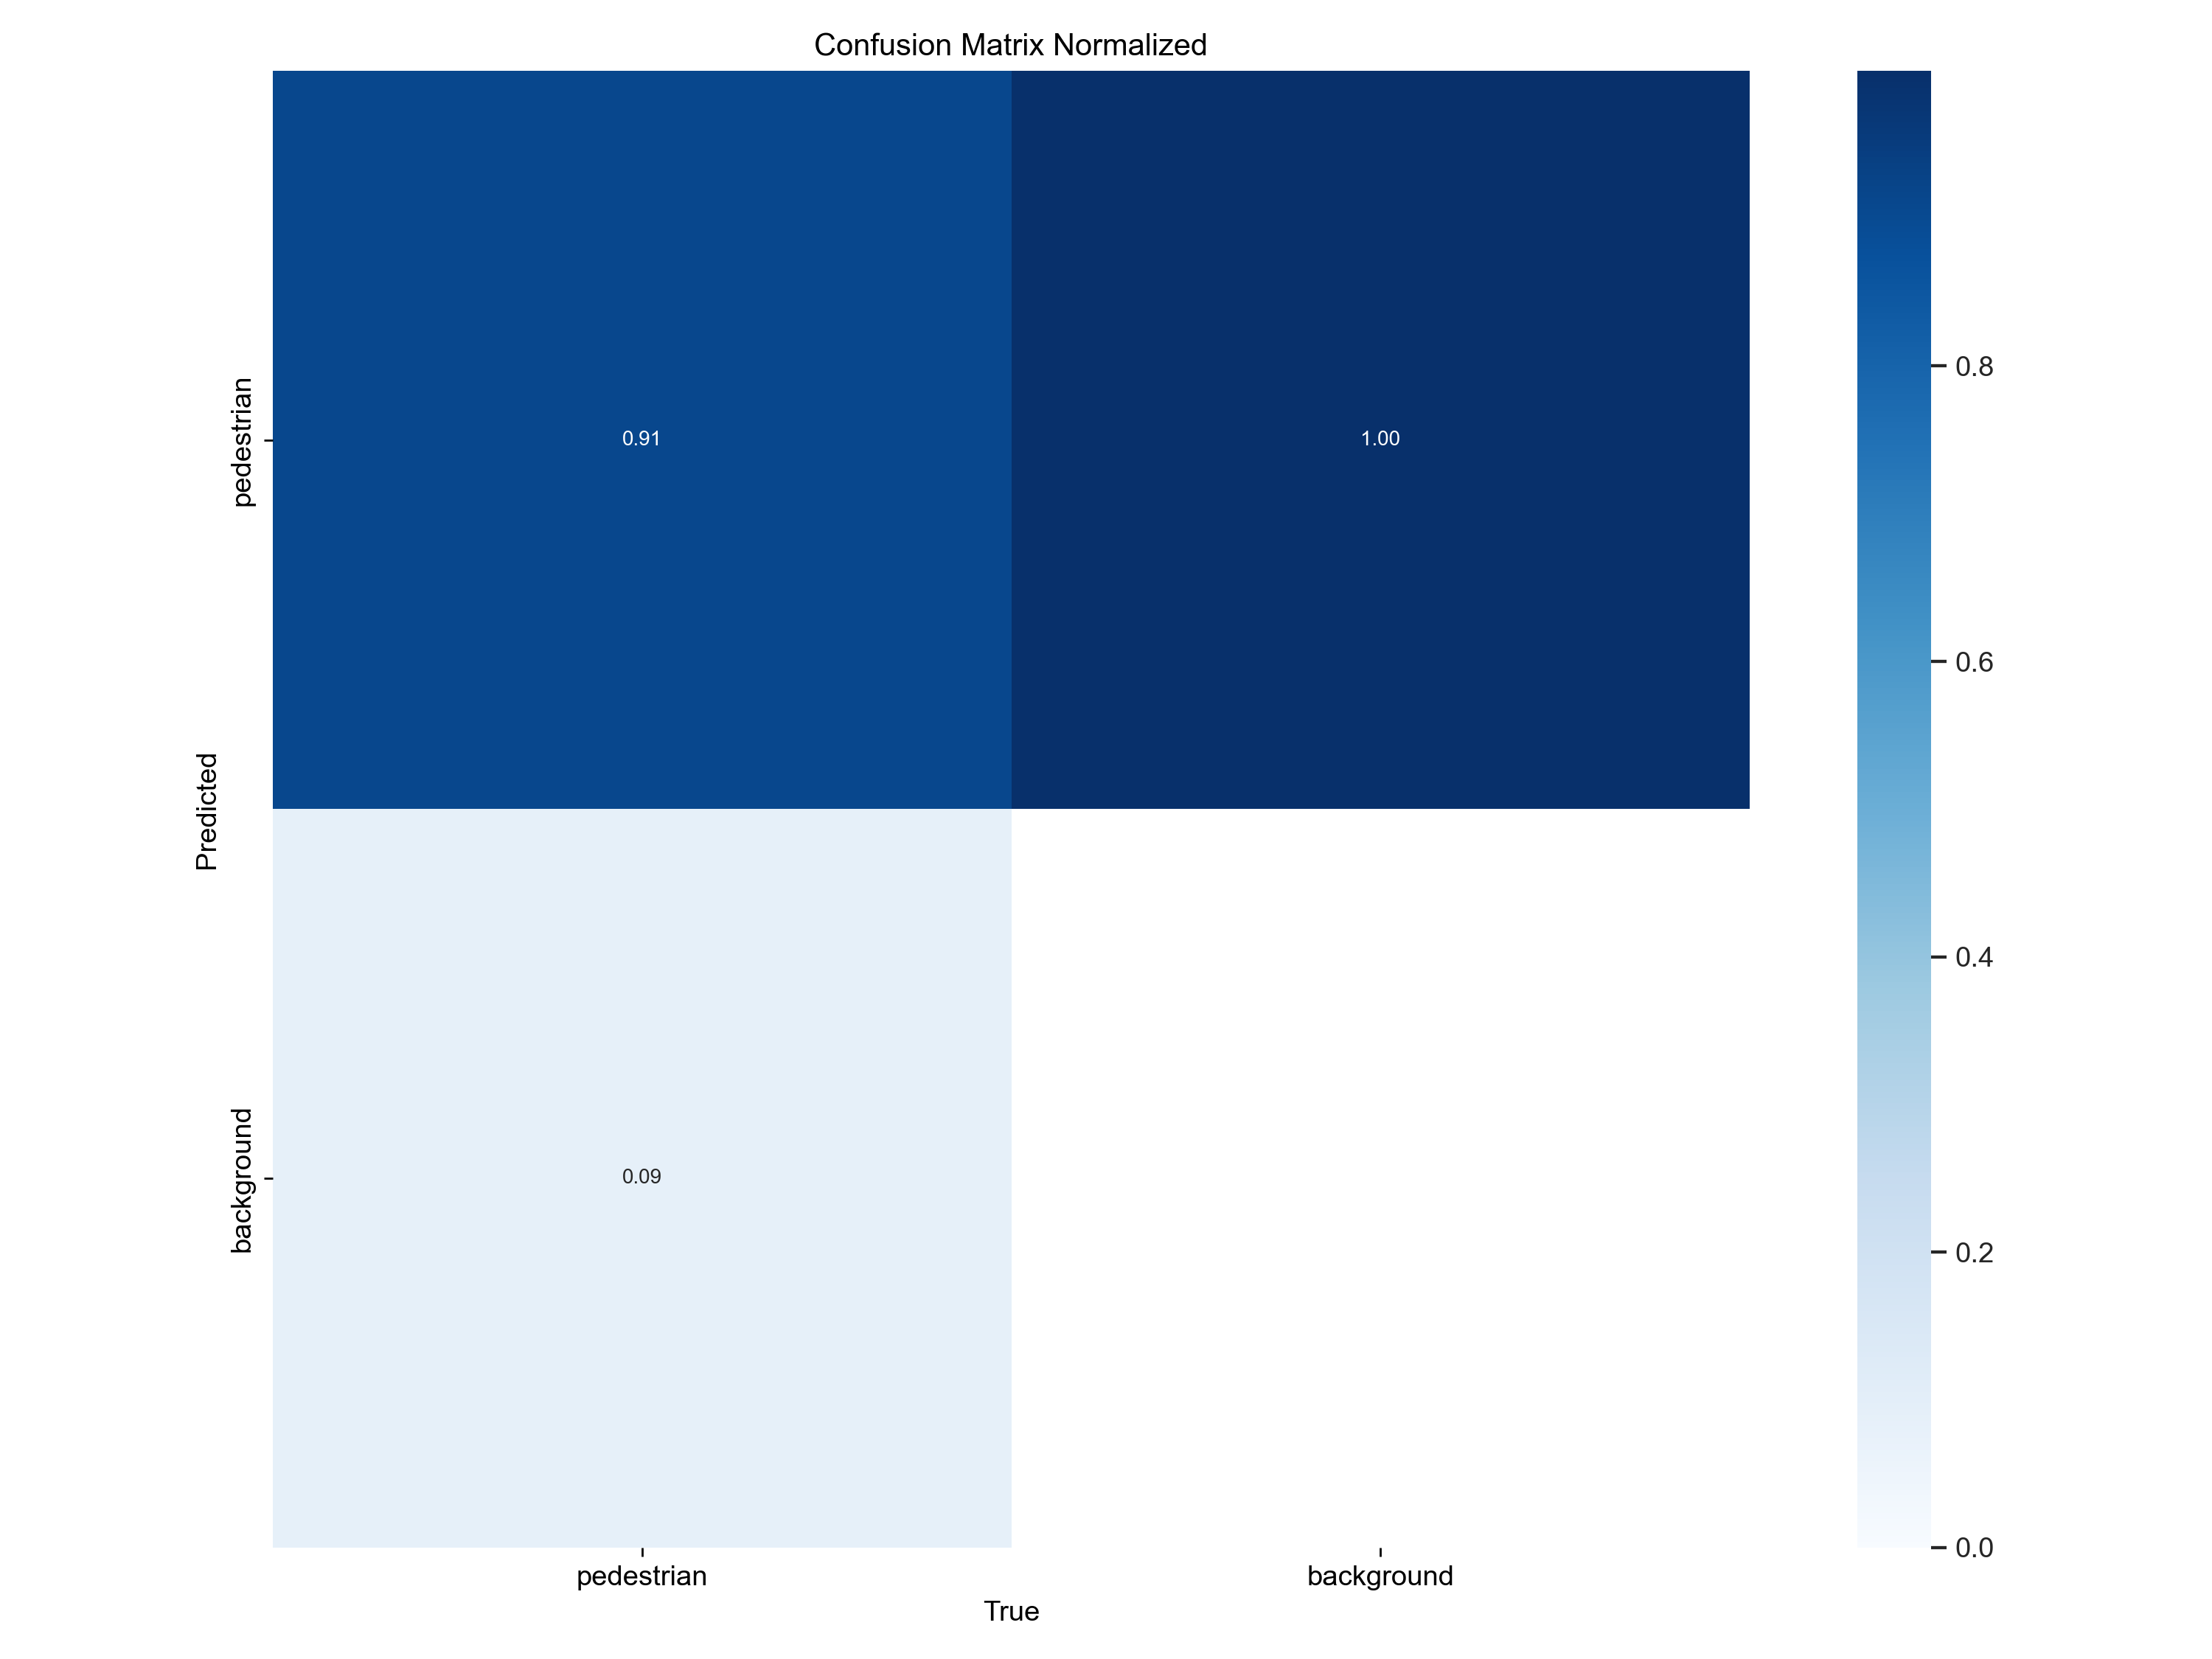

In [20]:
from IPython.display import Image as NotebookImage, display

for filename in ('results.png', 'PR_curve.png', 'confusion_matrix_normalized.png'):
    file_path = run_dir / filename
    if file_path.exists():
        print(filename)
        display(NotebookImage(filename=str(file_path)))

## 5. Test on unseen images

The test split was never used to update model weights. Compare the predicted boxes with the reference boxes for the same image.

Ultralytics 8.3.0  Python-3.13.14 torch-2.14.0+cpu CPU (12th Gen Intel Core(TM) i5-12500H)
YOLO11n summary (fused): 238 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


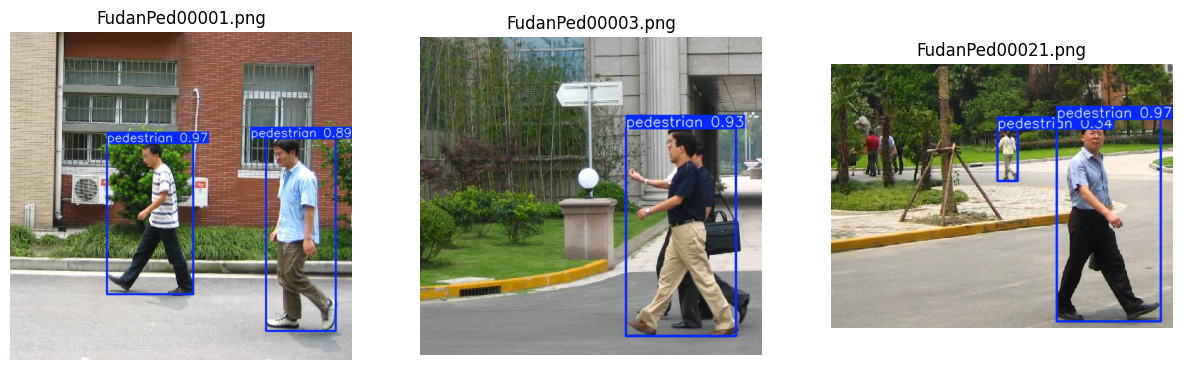

In [22]:
test_images = sorted((dataset_root / 'test' / 'images').glob('*.png'))[:3]
prediction_results = best_model.predict(
    source=[str(path) for path in test_images],
    imgsz=512,
    conf=0.25,
    device='cpu',
    verbose=False,
)

figure, axes = plt.subplots(1, len(prediction_results), figsize=(5 * len(prediction_results), 5))
if len(prediction_results) == 1:
    axes = [axes]
for axes_item, prediction, image_path in zip(axes, prediction_results, test_images):
    axes_item.imshow(prediction.plot()[:, :, ::-1])
    axes_item.set_title(image_path.name)
    axes_item.axis('off')
plt.show()

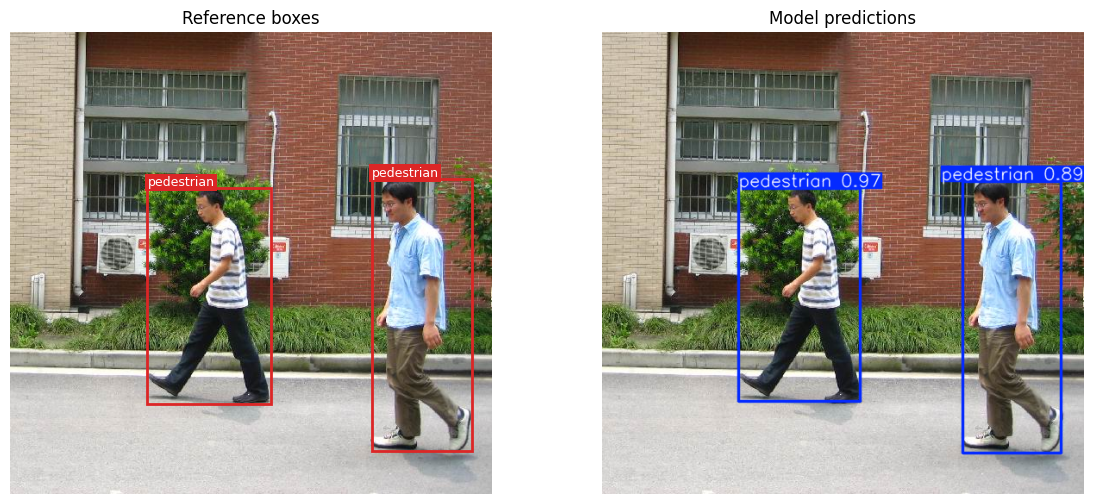

In [23]:
ground_truth_image, ground_truth_classes, ground_truth_boxes, ground_truth_path = dd.load_yolo_sample(
    dataset_root, 'test', index=0
)
first_prediction = prediction_results[0].plot()[:, :, ::-1]

figure, axes = plt.subplots(1, 2, figsize=(14, 6))
dd.plot_yolo_sample(axes[0], ground_truth_image, ground_truth_classes, ground_truth_boxes)
axes[0].set_title('Reference boxes')
axes[1].imshow(first_prediction)
axes[1].set_title('Model predictions')
axes[1].axis('off')
plt.show()

## Check your understanding

1. Why is mAP across IoU thresholds usually lower than mAP at IoU 0.50?

    mAP@0.50 only requires the predicted box to overlap the true box by 50%. mAP across thresholds (mAP@0.5:0.95) averages the score over stricter IoU requirements (up to 95% overlap). Stricter overlapping is harder to achieve, so the average score drops.
2. Choose one test image. Compare its prediction with the reference boxes. Identify one correct detection; if you see a missed or extra box, describe a likely visual reason.

    Correct detection: The model perfectly identified a clear, fully visible pedestrian with high confidence and drew a tight box, contributing to the high mAP@0.50 of 0.9295 (92.95%) on the test set.

    Missed box (False Negative): I can see a missed person, it is likely a pedestrian in the far background or partially occluded by a tree/another person. This explains why the Recall is 0.842 (the model missed about 15% of people).


3. Why must test images remain outside both augmentation and training?

    To prevent data leakage. If the model sees augmented versions of the test images during training, it will memorize their specific features. Keeping the test set completely unseen provides a fair, unbiased evaluation of how the model will perform on new, real-world images.
4. Name one training-data improvement you would try before changing the model architecture.

    Collect and add more annotated training images that specifically feature hard negatives (shadows, mannequins, people partially hidden) or apply more diverse data augmentation (e.g., varying brightness, cropping) to help the model generalize better.

## 6. Test the detector on a new scene

Choose one new scene containing at least one pedestrian: either one image or a short 5–15 second video (MP4 is recommended). Do not use an image from the Penn-Fudan dataset. Put exactly one file (JPG, JPEG, PNG, MP4, MOV, or AVI) in `work/student_input/`. In Google Colab, the next cell opens an upload dialog if the folder is empty; in VS Code, copy the file into that folder.

The next cell runs the trained model at confidence thresholds 0.25 and 0.50, so you can see how the threshold changes the predicted boxes. It displays annotated images and saves annotated videos in `work/student_runs/`. If you run the task again, leave only one supported input file in `work/student_input/`.

Results saved to c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\student_runs\conf_25
Confidence 0.25: c:\Users\Alina\OneDrive\Desktop\СV\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\student_runs\conf_25


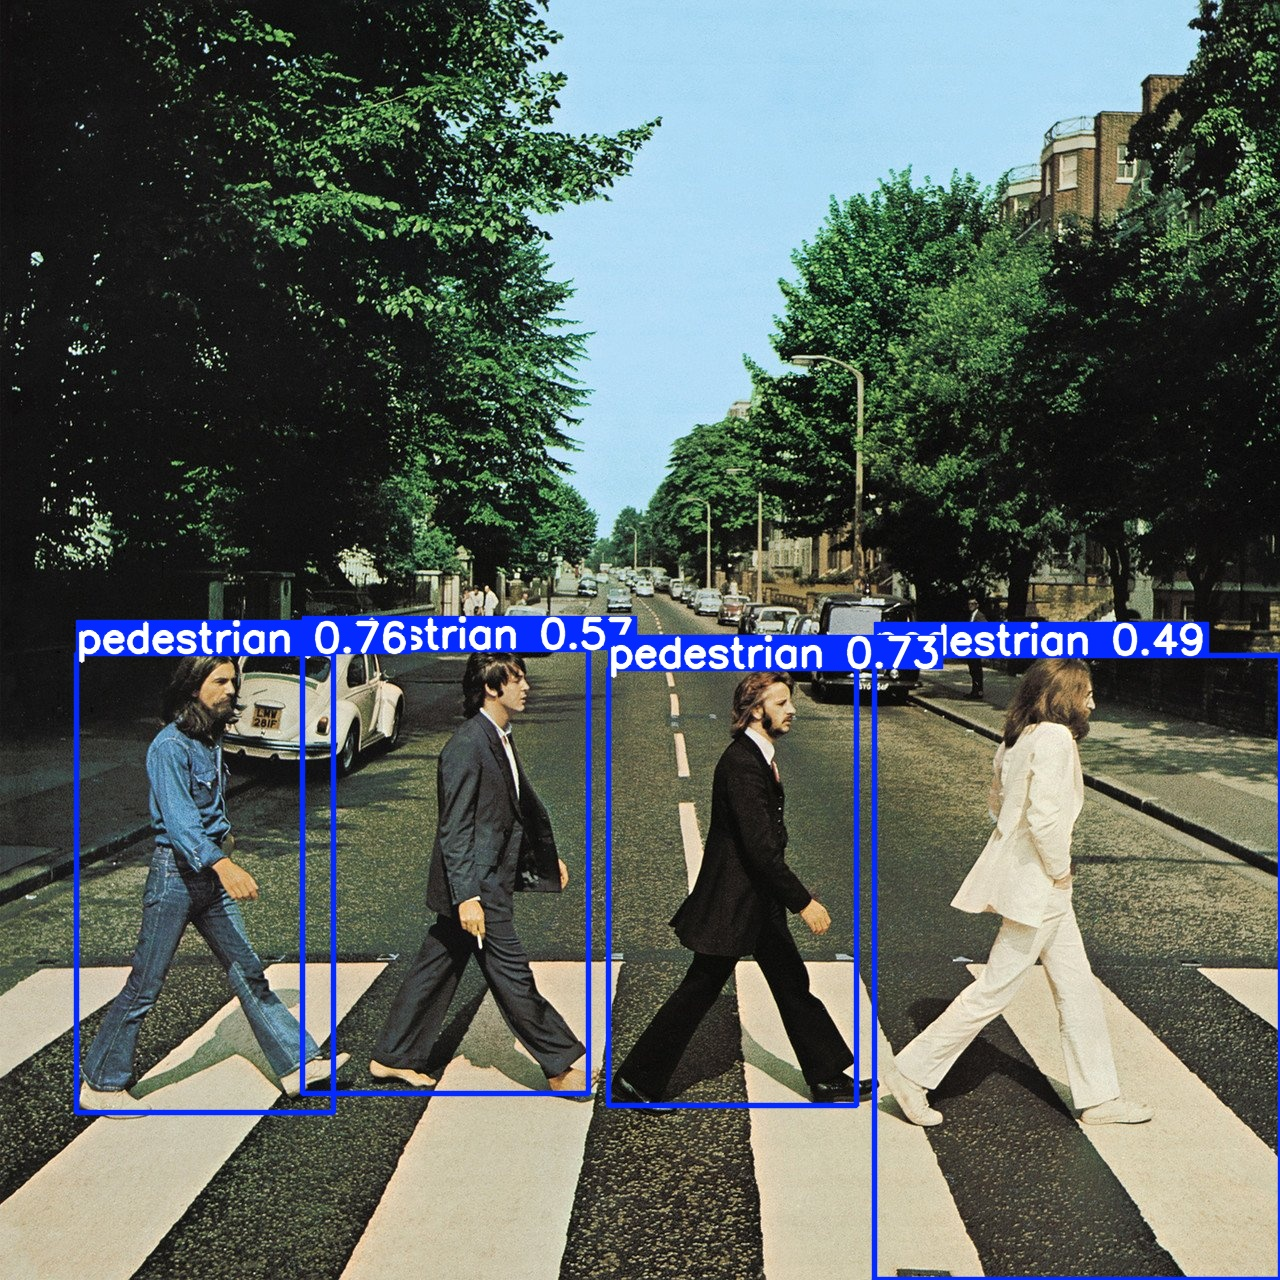

Results saved to c:\Users\Alina\OneDrive\Desktop\V\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\student_runs\conf_50
Confidence 0.50: c:\Users\Alina\OneDrive\Desktop\СV\Deep-Learning-for-Computer-Vision\Labs\Obj_detection\Lab12\work\student_runs\conf_50


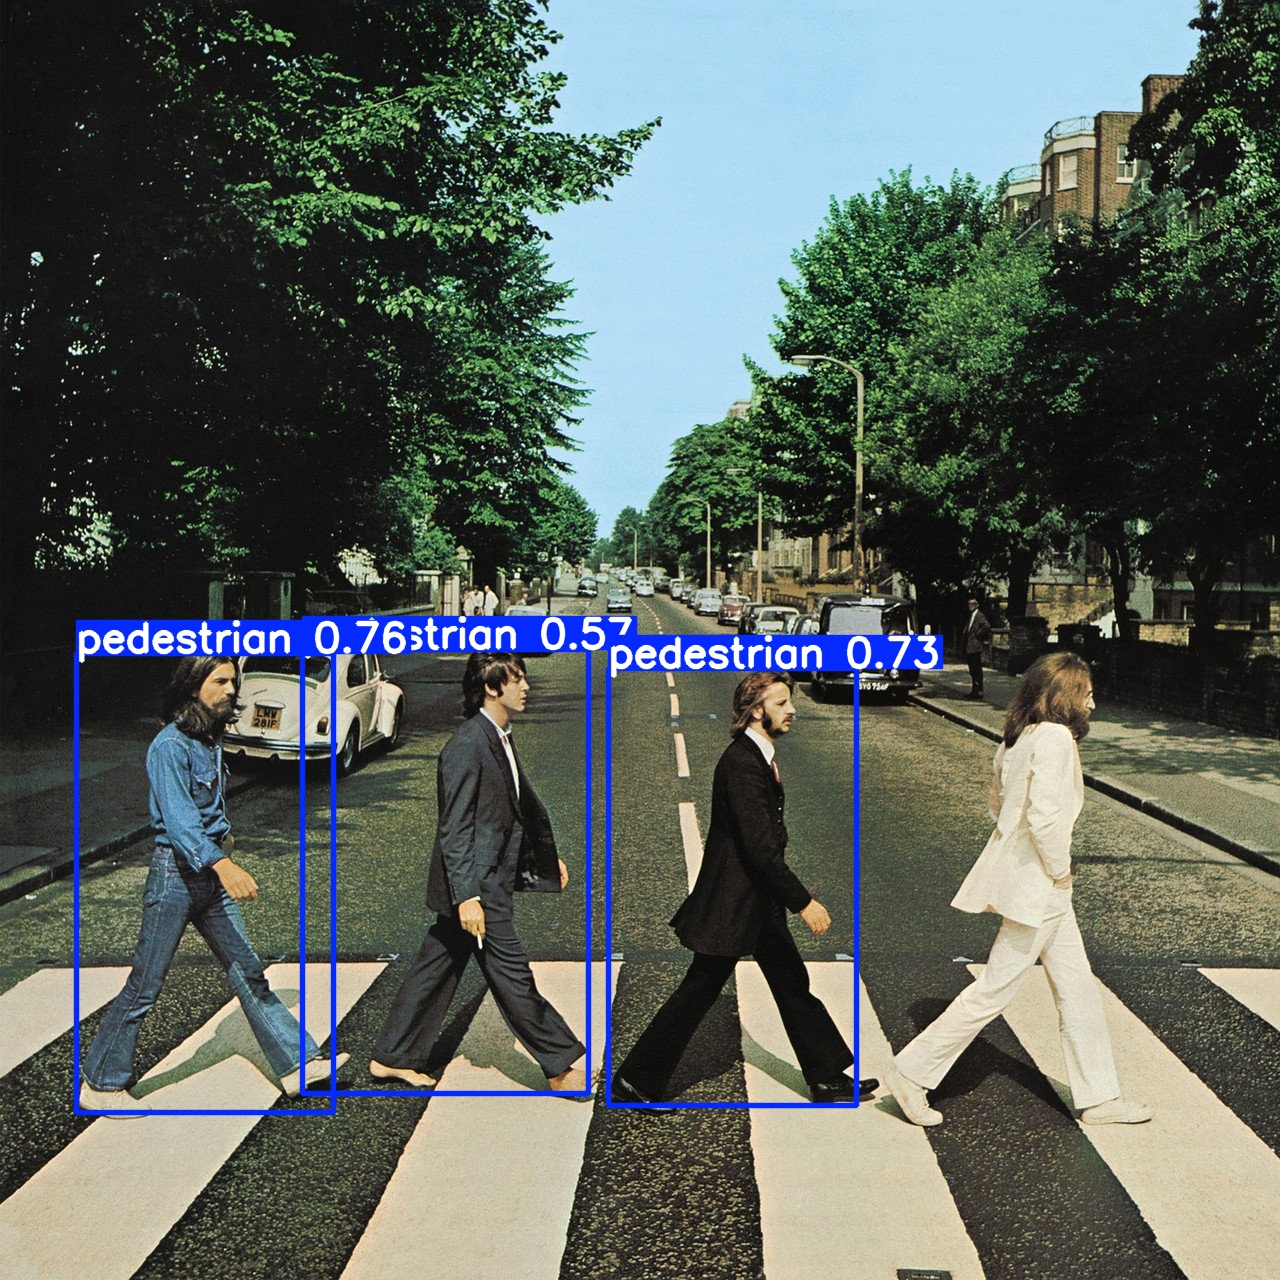

In [25]:
from IPython.display import Image as NotebookImage, display

student_input_dir = workspace / 'student_input'
student_input_dir.mkdir(exist_ok=True)
image_suffixes = {'.jpg', '.jpeg', '.png'}
video_suffixes = {'.mp4', '.mov', '.avi'}
supported_suffixes = image_suffixes | video_suffixes
student_sources = sorted(
    path for path in student_input_dir.iterdir()
    if path.is_file() and path.suffix.lower() in supported_suffixes
)
if not student_sources and 'google.colab' in sys.modules:
    from google.colab import files

    uploaded_files = files.upload()
    for filename, contents in uploaded_files.items():
        (student_input_dir / Path(filename).name).write_bytes(contents)
    student_sources = sorted(
        path for path in student_input_dir.iterdir()
        if path.is_file() and path.suffix.lower() in supported_suffixes
    )
if len(student_sources) != 1:
    print(
        f'Add exactly one image or video to {student_input_dir} before running this task. '
        f'Found {len(student_sources)} supported files.'
    )
else:
    student_source = student_sources[0]
    is_video = student_source.suffix.lower() in video_suffixes
    student_run_root = workspace / 'student_runs'
    student_run_root.mkdir(exist_ok=True)

    for confidence in (0.25, 0.50):
        run_name = f'conf_{int(confidence * 100):02d}'
        output_dir = student_run_root / run_name
        predictions = best_model.predict(
            source=str(student_source),
            imgsz=512,
            conf=confidence,
            device=0,
            save=True,
            project=str(student_run_root),
            name=run_name,
            exist_ok=True,
            stream=is_video,
            verbose=False,
        )
        if is_video:
            for _ in predictions:
                pass

        print(f'Confidence {confidence:.2f}: {output_dir}')
        if not is_video:
            saved_images = sorted(
                path for path in output_dir.iterdir()
                if path.suffix.lower() in image_suffixes
            )
            if saved_images:
                display(NotebookImage(filename=str(saved_images[0])))